In [22]:
%matplotlib inline

from pathlib import Path

import pandas as pd
import numpy as np
from sklearn import tree, metrics
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV

import matplotlib.pylab as plt
import matplotlib.pyplot as plt

!pip install dmba
from dmba import plotDecisionTree, classificationSummary, regressionSummary, liftChart, gainsChart

!pip install graphviz
import graphviz

import seaborn as sns

!pip install pydotplus
import pydotplus

In [2]:
# Mounting the Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [13]:
# Load datasets
SBA_df = pd.read_csv('/content/drive/My Drive/MSBA/MSBA BA Project/SBA_clean2.csv')

# Best model: Random Forest

In [14]:
# List of variables with only two categories; we want to drop one dummy to avoid redundancy
two_option_vars = ['RevLineCr', 'Term_Category', 'Recession']

# Loop to create dummies for variables with 2 options (drop_first=True)
for col in two_option_vars:
    SBA_df = pd.get_dummies(SBA_df, columns=[col], drop_first=True, dtype=int)

# List of remaining categorical variables for which we create full dummy sets
multi_option_vars = ['UrbanRural']

# Loop to create dummies for other categorical variables (drop_first=False)
for col in multi_option_vars:
    SBA_df = pd.get_dummies(SBA_df, columns=[col], drop_first=False, dtype=int)
# Split into 60/40 data
train_df, valid_df = train_test_split(SBA_df, test_size=0.4, random_state=1)
print(train_df.shape, valid_df.shape)

(284117, 9) (189412, 9)


In [15]:
# Split train and valid into X and y
train_X = train_df.drop(columns =['MIS_Status'],axis = 1)
train_y = train_df['MIS_Status']
valid_X = valid_df.drop(columns =['MIS_Status'],axis = 1)
valid_y = valid_df['MIS_Status']
train_X.head()

,DisbursementGross,SBA_Appv,RevLineCr_1,Term_Category_Below 10 years,Recession_1,UrbanRural_0,UrbanRural_1,UrbanRural_2
178126,60900.0,30450.0,0,1,1,0,1,0
244880,545000.0,283400.0,0,0,0,0,1,0
141699,15000.0,7500.0,0,1,1,0,1,0
168395,25000.0,12500.0,0,1,1,0,1,0
626,125000.0,62500.0,0,1,0,0,1,0


In [16]:
# Define the class weights: Class 1 has weight 5, and Class 0 has weight 1
class_weights = {1: 5, 0: 1}

# Initialize the RandomForestClassifier with class weights
rfModel = RandomForestClassifier(
    n_estimators=100,  # Number of trees in the forest
    random_state=1,     # For reproducibility
    class_weight=class_weights  # Use the custom class weights
)

# Fit the model with training data
rfModel.fit(train_X, train_y)

# Evaluate the model
train_score = rfModel.score(train_X, train_y)
print(f"Random Forest Training Accuracy: {train_score:.2f}")

Random Forest Training Accuracy: 0.82


Accuracy:  0.6783466728612759


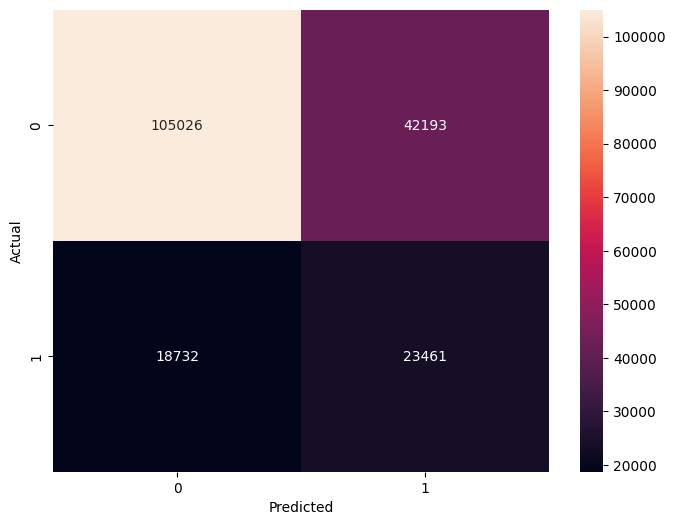

In [17]:
#Confusion Matrix
y_pred = rfModel.predict(valid_X)
confusion_matrix = pd.crosstab(valid_y, y_pred, rownames=['Actual'], colnames=['Predicted'])
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix, annot=True, fmt='g')
print('Accuracy: ',metrics.accuracy_score(valid_y, y_pred))
plt.show()

In [18]:
# y_Pred
y_pred = rfModel.predict(valid_X)

# Precision (Positive class is 'Acceptors')
precision = metrics.precision_score(valid_y, y_pred, pos_label=1)

# Recall (Sensitivity) or True Positive Rate
recall = metrics.recall_score(valid_y, y_pred, pos_label=1)

# F1 Score (harmonic mean of Precision and Recall)
f1 = metrics.f1_score(valid_y, y_pred, pos_label=1)

# Calculate the confusion matrix
cm = metrics.confusion_matrix(valid_y, y_pred)

# Extract True Negatives (TN), False Positives (FP), False Negatives (FN), True Positives (TP)
TN, FP, FN, TP = cm.ravel()

# Specificity (True Negative Rate)
specificity = TN / (TN + FP)

# Scores dataframe
scores = pd.DataFrame({
    'Model': ['RF Tree'],
    'Precision': [precision],
    'Recall': [recall],
    'F1 Score': [f1],
    'Specificity': [specificity]
})

scores

,Model,Precision,Recall,F1 Score,Specificity
0,RF Tree,0.357343,0.55604,0.435079,0.7134


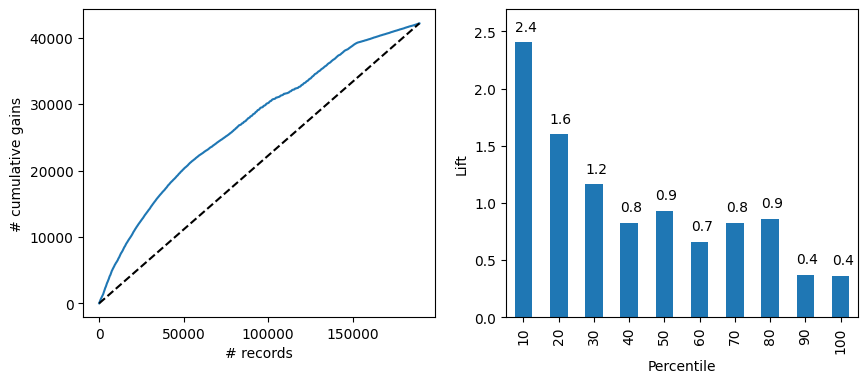

In [19]:
# Lift and Decile Charts

# Step 1: Calculate predicted probabilities for the training set
valid_proba = rfModel.predict_proba(valid_X)


# Step 2: Create a DataFrame with actual, predicted probabilities, and predicted labels for the training set
valid_result = pd.DataFrame({
    'actual': valid_y,
    'p(0)': [p[0] for p in valid_proba],
    'p(1)': [p[1] for p in valid_proba],
    'predicted': rfModel.predict(valid_X)
})

# Step 3: Sort DataFrame by p(1)
valid_df = valid_result.sort_values(by=['p(1)'], ascending=False)

# Convert 'actual' from categorical to numeric
valid_df['actual'] = valid_df['actual'].astype(int)

# Step 4: Plot Gains and Lift charts for the training set
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

gainsChart(valid_df.actual, ax=axes[0])
liftChart(valid_df.actual, title=False)

plt.show()

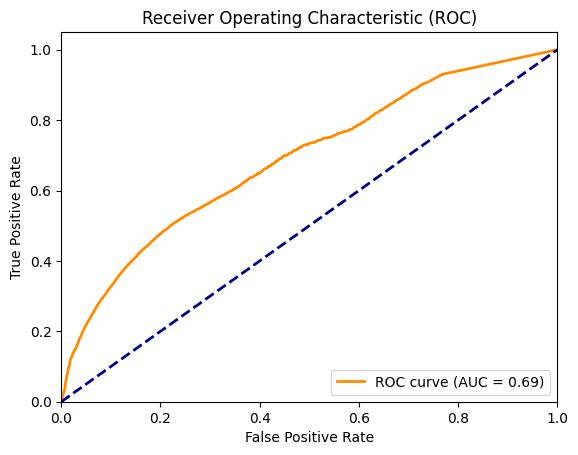

In [23]:
# ROC Curve
# Compute ROC curve and AUC
fpr, tpr, thresholds = metrics.roc_curve(valid_y, valid_proba[:, 1])
roc_auc = metrics.auc(fpr, tpr)

# Plot ROC curve
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc='lower right')
plt.show()

## Calculate Net Profit and Cut-off

In [24]:
# Ensure all arrays are numpy arrays of the same shape
disbursement_gross = np.array(train_X['DisbursementGross'])
actual_y = np.array(train_y)

# Get predicted probabilities for the positive class
pred_prob = rfModel.predict_proba(train_X)[:, 1]  # Probabilities for class 1 ("Default")

# Initialize an array to store net profits for each threshold
thresholds = np.linspace(0.01, 0.99, 100)  # Range of thresholds from 0.01 to 0.99
net_profits = np.zeros_like(thresholds)

# Loop over each threshold and calculate the net profit
for i, threshold in enumerate(thresholds):
    # Classify based on the threshold
    pred_y = (pred_prob >= threshold).astype(int)

    # Calculate net profit based on the classification results (same logic as you provided)
    net_profit = np.zeros_like(actual_y, dtype=float)

    # Case 1: Correctly classified as "Paid in full" (Actual = 0, Predicted = 0)
    mask = (actual_y == 0) & (pred_y == 0)
    net_profit[mask] = 0.05 * disbursement_gross[mask]

    # Case 2: Incorrectly classified as "Paid in full" (Actual = 1, Predicted = 0)
    mask = (actual_y == 1) & (pred_y == 0)
    net_profit[mask] = -0.05 * disbursement_gross[mask] * 5

    # Case 3: Correctly classified as "Default" (Actual = 1, Predicted = 1)
    mask = (actual_y == 1) & (pred_y == 1)
    net_profit[mask] = 0

    # Case 4: Incorrectly classified as "Default" (Actual = 0, Predicted = 1)
    mask = (actual_y == 0) & (pred_y == 1)
    net_profit[mask] = 0  # No profit or loss for incorrect "default", adjust if necessary

    # Calculate total net profit for this threshold
    net_profits[i] = np.sum(net_profit)

# Find the threshold that maximizes the net profit
best_threshold = thresholds[np.argmax(net_profits)]
max_net_profit = np.max(net_profits)

# Output the best threshold and corresponding net profit
print(f"Best Threshold: {best_threshold:.2f}")
print(f"Maximum Net Profit: {max_net_profit:,.2f} USD")

Best Threshold: 0.43
Maximum Net Profit: 1,689,173,283.50 USD


In [27]:
# Step 1: Get propensities (probabilities for class 1)
propensities = rfModel.predict_proba(valid_X)[:, 1]  # Probabilities for class 1

# Step 2: Create DataFrame with propensities, actual values, and DisbursementGross
results_df = pd.DataFrame({
    'Propensity': propensities,
    'Actual': valid_y,
    'DisbursementGross': valid_X['DisbursementGross']
})

# Step 3: Sort by Propensity (ascending order)
results_df = results_df.sort_values(by='Propensity', ascending=True)

# Step 4: Calculate Net Profit based on conditions
results_df['NetProfit'] = 0  # Initialize NetProfit column with 0
results_df['NetProfit'] = results_df['NetProfit'].astype(float)
results_df.loc[(results_df['Actual'] == 0) & (results_df['Propensity'] <= 0.43), 'NetProfit'] = 0.05 * results_df['DisbursementGross']
results_df.loc[(results_df['Actual'] == 1) & (results_df['Propensity'] <= 0.43), 'NetProfit'] = -0.05 * results_df['DisbursementGross']

# Step 5: Apply cutoff (0.43) to predictions
results_df['Predicted'] = (results_df['Propensity'] > 0.43).astype(int)

# Step 6: Show results where cutoff is reached (where 'Predicted' becomes 1)
cutoff_reached_df = results_df[results_df['Predicted'] == 1]

# Display results
print(cutoff_reached_df[['Propensity', 'Actual', 'Predicted', 'NetProfit']])

        Propensity  Actual  Predicted  NetProfit
45597     0.430108       1          1        0.0
264282    0.430112       1          1        0.0
283386    0.430112       0          1        0.0
305569    0.430112       0          1        0.0
285182    0.430112       0          1        0.0
...            ...     ...        ...        ...
82561     1.000000       1          1        0.0
133685    1.000000       0          1        0.0
368487    1.000000       1          1        0.0
375348    1.000000       1          1        0.0
61525     1.000000       0          1        0.0

[74997 rows x 4 columns]


In [29]:
# To see the last row
cutoff_row = results_df[results_df['Predicted'] == 1].iloc[0]
print(f"Cutoff row details: {cutoff_row}")

Cutoff row details: Propensity               0.430108
Actual                   1.000000
DisbursementGross    83700.000000
NetProfit                0.000000
Predicted                1.000000
Name: 45597, dtype: float64


**We reach the maximum net profit at 74,997 rows into the validation set.**